In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\hydra\AppData\Local\Temp\ipykernel_15496\4132874536.py:1: SyntaxWarning: invalid escape sequence '\d'
  data = pd.read_pickle('..\data\diffusion\diffusion_widom_11092025.pkl')


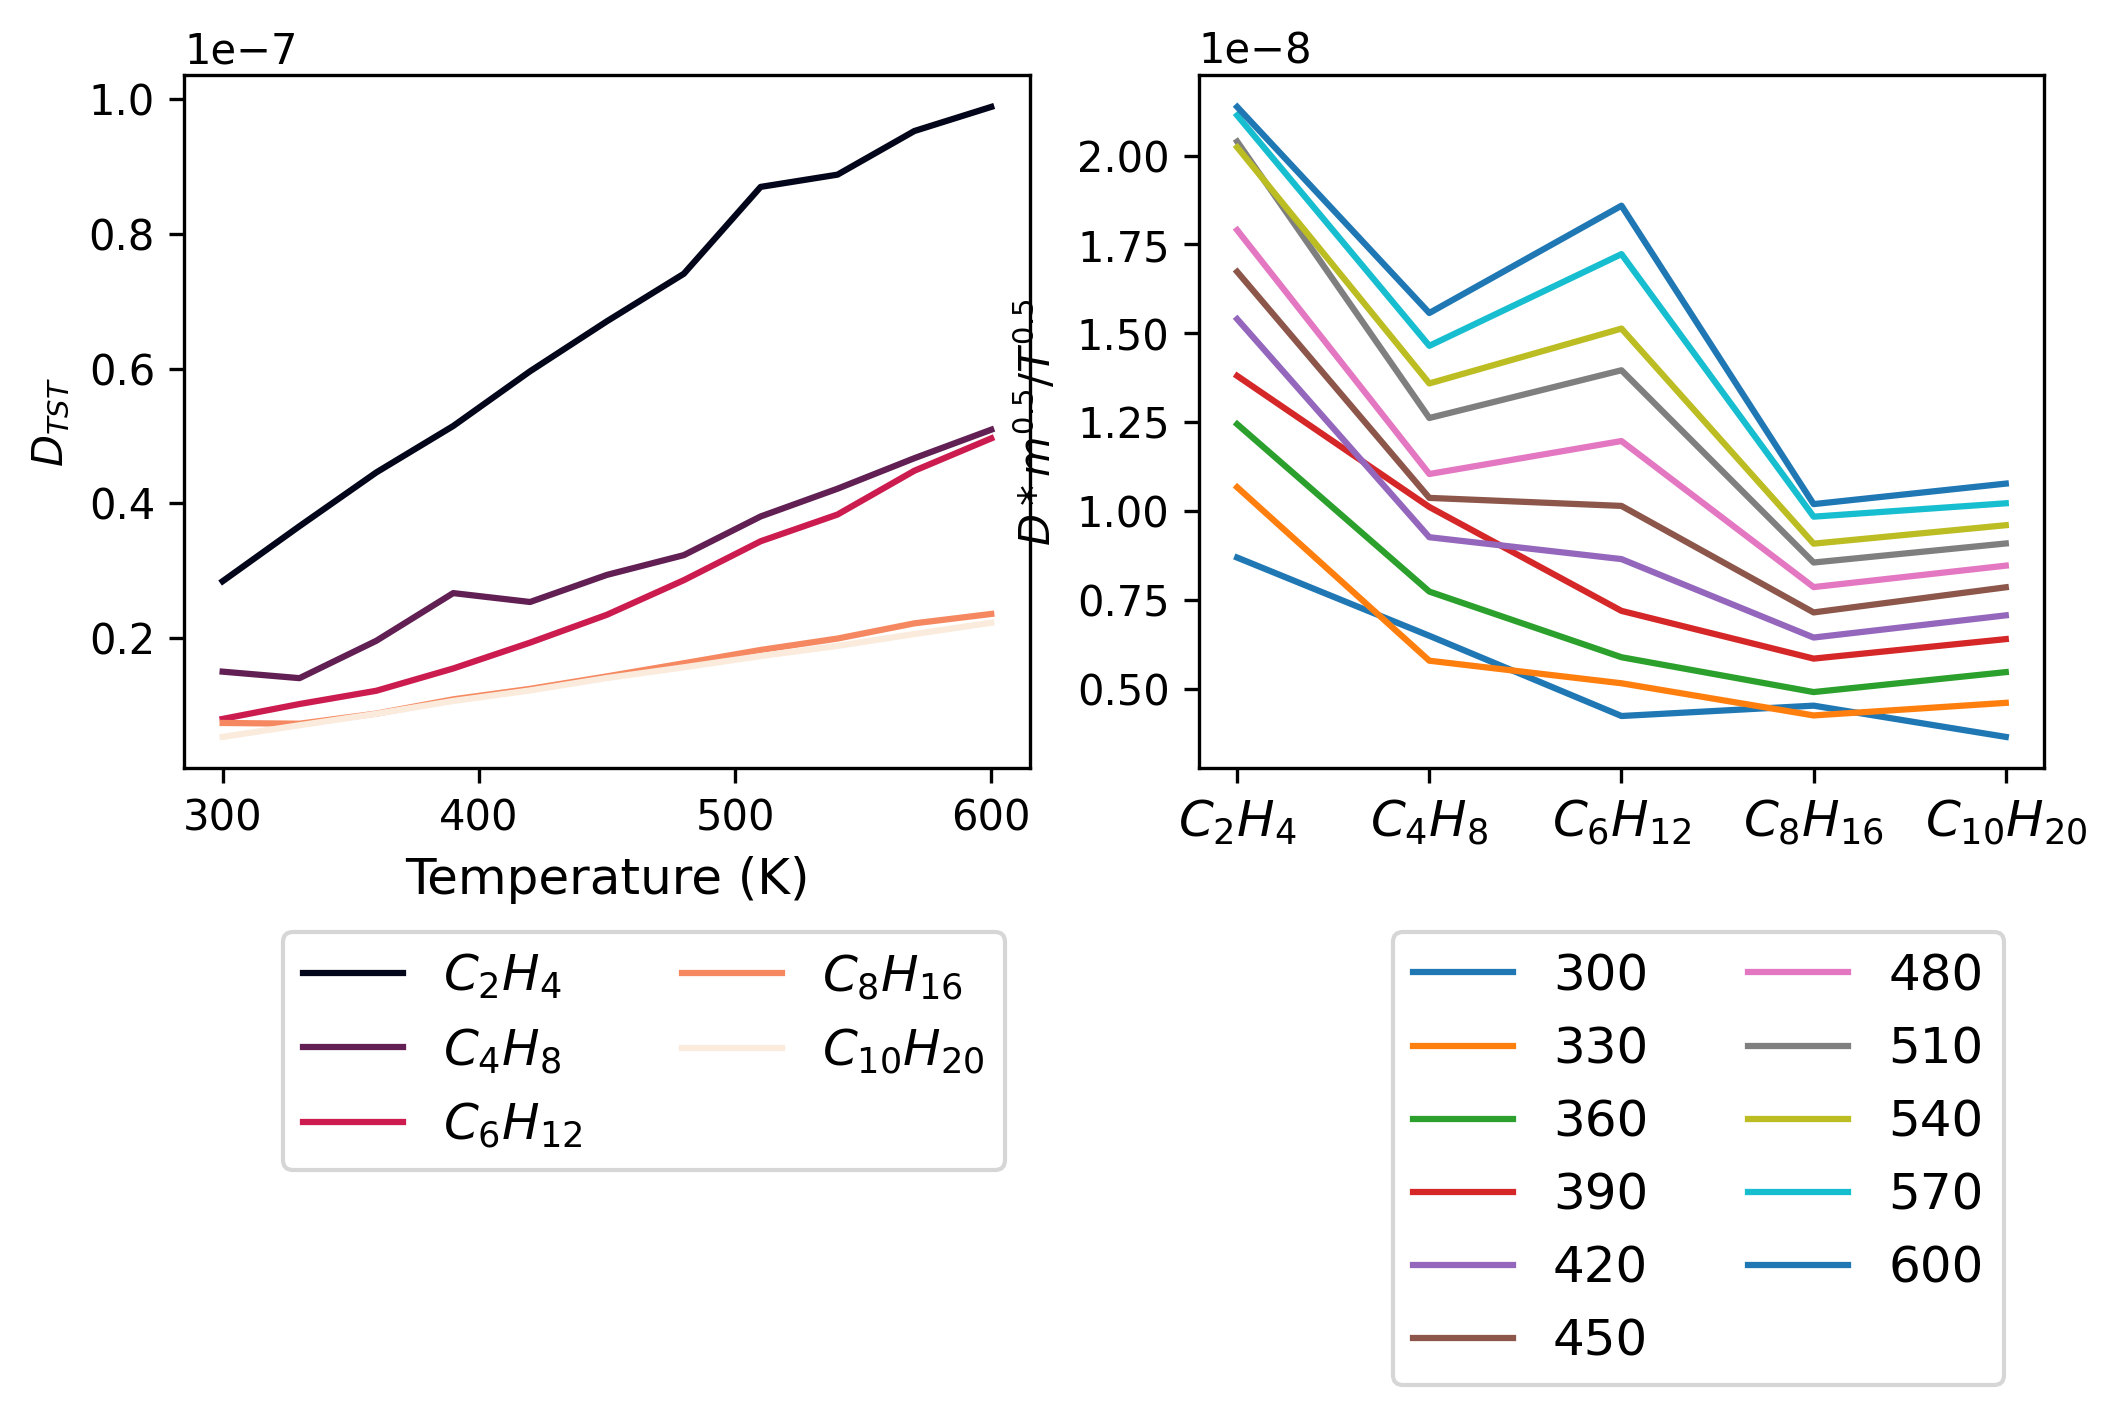

In [2]:
data = pd.read_pickle('..\data\diffusion\diffusion_widom_11092025.pkl')
data['D_TST'] = data['D'] 

def mass_calc(n):
    """
    Calculate the mass of a molecule based on the number of atoms.
    """
    m = 1.008 * 2 * n + 12.01 * n
    return m

data['D_norm'] = data['D'] / data['temperature'] ** 0.5 * mass_calc(data['n']) ** 0.5

fig, axs = plt.subplots(1, 2, figsize=(8, 3), dpi=300)
sns.lineplot(x='temperature', y='D_TST', hue='n', data=data, palette='rocket', ax=axs[0])
sns.lineplot(x='n', y='D_norm', hue='temperature', data=data.query('n <= 10'), palette='tab10', ax=axs[1])
axs[1].set_ylabel(r'$D * m^{0.5}/ T^{0.5}$')
axs[0].set_ylabel(r'$D_{TST}$')
axs[1].set_xticks(list(range(2, 11, 2)), [f'$C_{{{n}}}H_{{{2*n}}}$' for n in range(2, 11, 2)], fontsize=12)
handles, labels = axs[0].get_legend_handles_labels()
lables = [f'$C_{{{n}}}H_{{{2*n}}}$' for n in range(2, 11, 2)]
axs[0].legend(handles, lables, title='', fontsize=12,
            ncol=2, bbox_to_anchor=(1., -0.2),)
axs[0].set_xlabel('Temperature (K)', fontsize=12)
axs[1].set_xlabel('')
handles, labels = axs[1].get_legend_handles_labels()
axs[1].legend(handles, labels, title='', fontsize=12,   
            ncol=2, bbox_to_anchor=(.2, -0.2), loc='upper left')

box = axs[1].get_position()

It is not linear from sqrt(m) ... but as a placeholder it will be okay.

In [3]:
import joblib
from kinetic_model.constants.diffusion import DiffusionLinear

# 2) Fit & save
diff_model = DiffusionLinear()
diff_model.fit(data, D_col='D_TST')
joblib.dump(diff_model, '../data/processed/diffusion_model_11092025.pkl')

['../data/processed/diffusion_model_11092025.pkl']

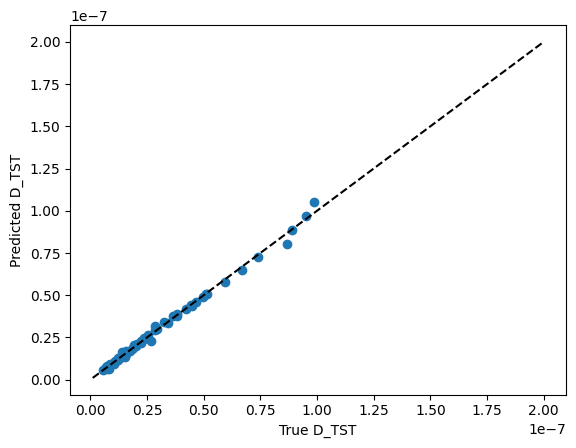

In [4]:
# 3) Later: load & predict
diff_loaded = joblib.load('../data/processed/diffusion_model_11092025.pkl')

y_pred = diff_loaded.predict(data[['temperature', 'n']])
y_true = data['D_TST'].to_numpy()
# 4) Plot
plt.scatter(y_true, y_pred)
plt.xlabel('True D_TST')
plt.ylabel('Predicted D_TST')
plt.plot([1e-9, 2e-7], [1e-9, 2e-7], 'k--')

In [5]:
from kinetic_model.constants.diffusion import DiffusionLinearExtrapPlaceHolder


diff_model_extrap = DiffusionLinearExtrapPlaceHolder()
diff_model_extrap.fit(data, D_col='D_TST')
joblib.dump(diff_model_extrap, '../data/processed/diffusion_extrap_place_holder_model.pkl')
model = joblib.load('../data/processed/diffusion_extrap_place_holder_model.pkl')
y_pred_extrap = model.predict(pd.DataFrame({'n': [2, 4, 6, 8, 10, 12, 14, 16], 'temperature': [300, 300, 301, 300, 300, 300, 300, 300]}))
y_pred_extrap

array([3.17188160e-08, 1.36091973e-08, 6.27152817e-09, 6.50112398e-09,
       5.93852313e-09, 5.36462531e-09, 4.96667794e-09, 4.64590180e-09])